In [1]:
import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '2'

import random
import numpy as np
import matplotlib.pyplot as plt
import copy
import math
import time
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
       torch.cuda.manual_seed(seed)
       torch.cuda.manual_seed_all(seed)
       torch.backends.cudnn.deterministic = False
       torch.backends.cudnn.benchmark = True

set_seed(SEED)

# Setup

In [2]:
PATH = "/home/jovyan/work/UFSC/ubiquos_tomato_village/dataset/tomato_village/tomato_village/Variant-a(Multiclass Classification)"

EPOCHS = 100
PATIENCE_ES = 100

BATCH_SIZE = 64


LR = 1e-3
MIN_LR = 1e-7
GRAD_CLIP = 1.0

IMG_SIZE = (224, 224)
MODEL_SAVE_PATH = "best__model.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {DEVICE}")

Device: cuda


# Dataset

In [3]:
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)

In [4]:
train_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.RandomHorizontalFlip(p=0.1),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

val_test_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

In [5]:
train_dir = os.path.join(PATH, "train")
val_dir = os.path.join(PATH, "val")
test_dir = os.path.join(PATH, "test")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=val_test_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transforms)

class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

if val_dataset.class_to_idx != class_to_idx:
    raise ValueError("As classes de treino e validação não estão alinhadas")

if test_dataset.class_to_idx != class_to_idx:
    raise ValueError("As classes de treino e teste não estão alinhadas")

pin_memory = DEVICE.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=pin_memory,
    persistent_workers=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=pin_memory,
    persistent_workers=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=pin_memory,
    persistent_workers=True,
)

print(f"Classes: {len(class_names)}")
print(
    f"Train: {len(train_dataset)} | "
    f"Val: {len(val_dataset)} | "
    f"Test: {len(test_dataset)}"
)

Classes: 8
Train: 3162 | Val: 902 | Test: 461


Distribuicao no treino:
  Early_blight                  : 347
  Healthy                       : 151
  Late_blight                   : 632
  Leaf Miner                    : 716
  Magnesium Deficiency          : 654
  Nitrogen Deficiency           : 251
  Pottassium Deficiency         : 50
  Spotted Wilt Virus            : 361


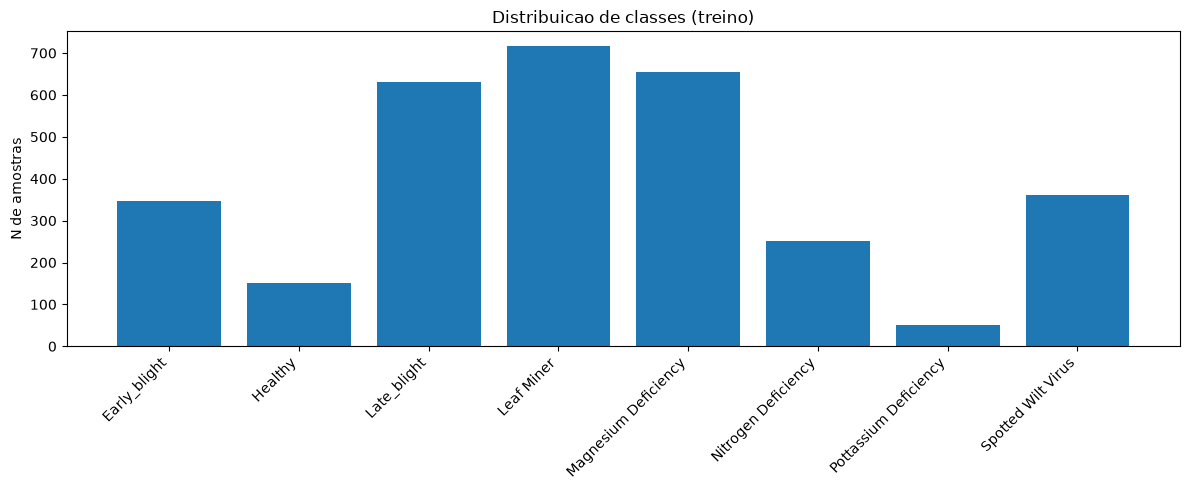

Class weights: [0.844589352607727, 1.2803298234939575, 0.625823438167572, 0.5879681706428528, 0.615207314491272, 0.9930554032325745, 2.224976062774658, 0.8280503749847412]


In [6]:
train_targets = np.asarray(train_dataset.targets)
train_counts = np.bincount(train_targets, minlength=len(class_names))

print("Distribuicao no treino:")
for name, count in zip(class_names, train_counts):
    print(f"  {name:30s}: {count}")

plt.figure(figsize=(12, 5))
plt.bar(class_names, train_counts)
plt.xticks(rotation=45, ha='right')
plt.ylabel("N de amostras")
plt.title("Distribuicao de classes (treino)")
plt.tight_layout()
plt.show()

class_weights = len(train_targets) / (
    len(class_names) * train_counts
)

class_weights = np.sqrt(class_weights)
class_weights = class_weights / class_weights.mean()

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)
print(f"Class weights: {class_weights.tolist()}")

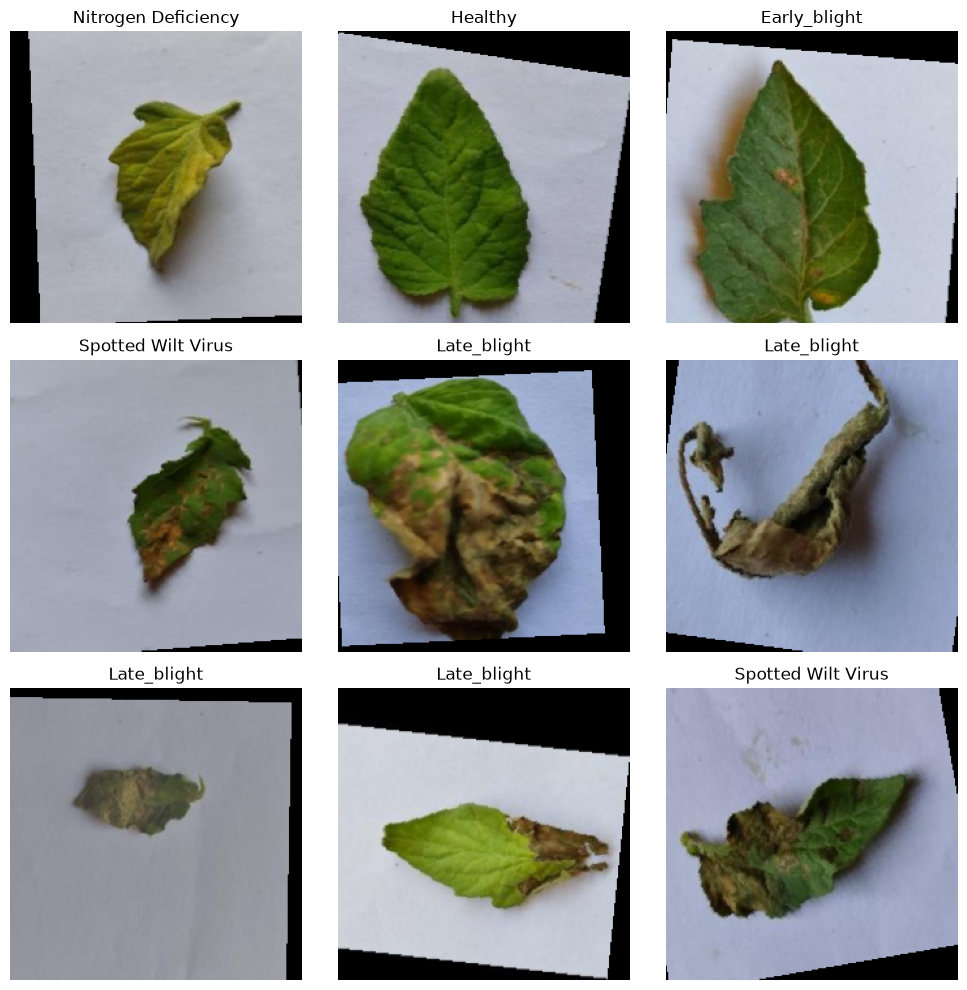

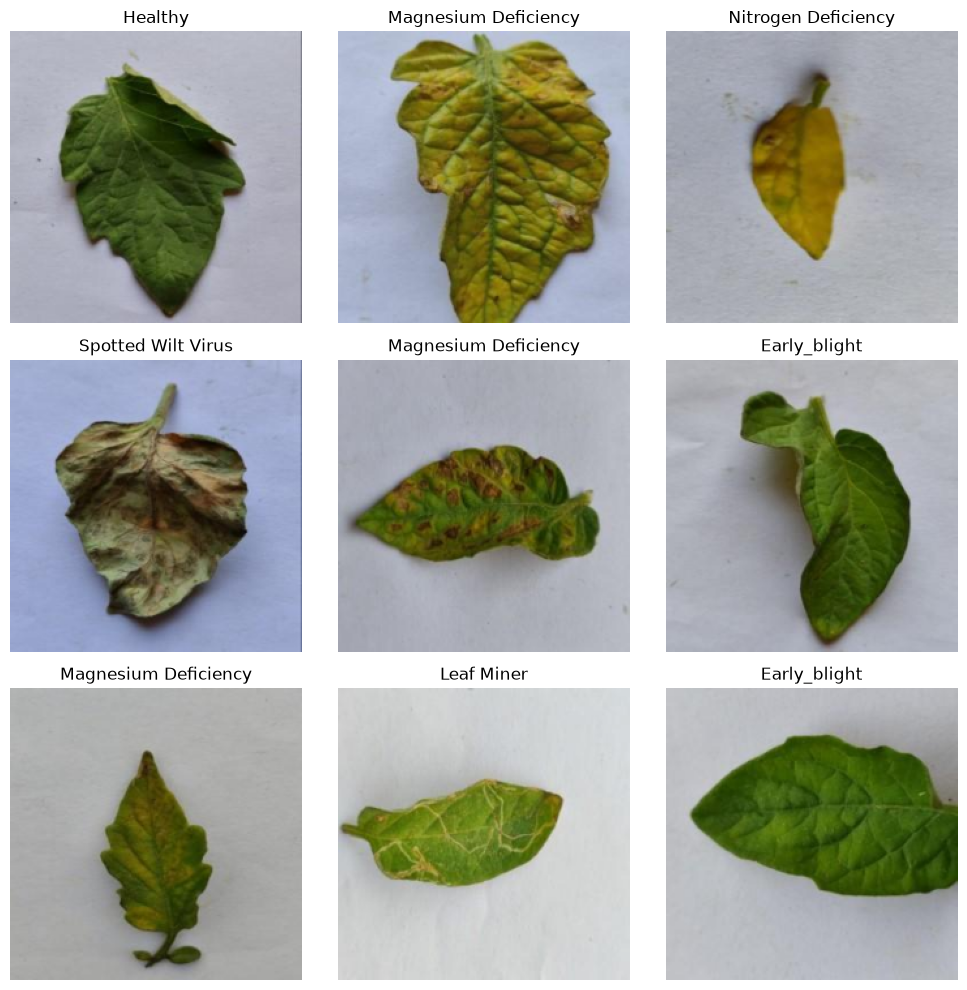

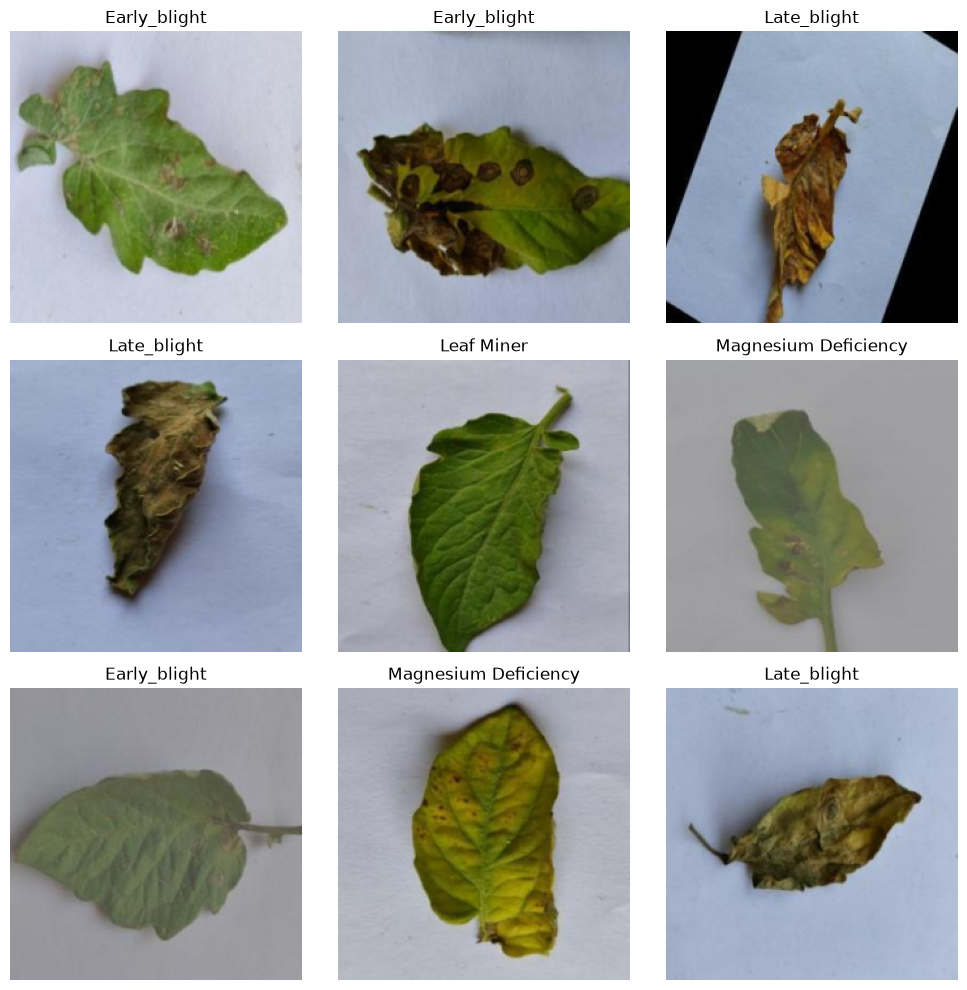

In [7]:
def plot_samples(dataset, class_names, num_samples=9):
    cols = 3
    rows = math.ceil(num_samples / cols)
    plt.figure(figsize=(10, 10))
    
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    indices = random.sample(range(len(dataset)), num_samples)
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        
        ax = plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)
        plt.title(class_names[label])
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

plot_samples(train_dataset, class_names)
plot_samples(test_dataset, class_names)
plot_samples(val_dataset, class_names)

# Model

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvDPUnit(nn.Module):
    def __init__(self, in_channels, out_channels, with_bn_relu=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=True)
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            3,
            1,
            1,
            bias=True,
            groups=out_channels
        )
        self.with_bn_relu = with_bn_relu
        if with_bn_relu:
            self.bn = nn.BatchNorm2d(out_channels)
            self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        if self.with_bn_relu:
            x = self.bn(x)
            x = self.relu(x)
        return x


class ConvHead(nn.Module):
    def __init__(self, in_channels, mid_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, mid_channels, 3, 2, 1, bias=True)
        self.bn = nn.BatchNorm2d(mid_channels)
        self.relu = nn.ReLU(inplace=True)
        self.proj = ConvDPUnit(mid_channels, out_channels)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return self.proj(x)


class Conv4LayerBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = ConvDPUnit(in_channels, in_channels)
        self.conv2 = ConvDPUnit(in_channels, out_channels)

    def forward(self, x):
        x = self.conv1(x)
        return self.conv2(x)


class YuNetBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.downsample_idx = {0, 2, 3, 4}
        self.out_idx = {3, 4, 5}
        self.stages = nn.ModuleList([
            ConvHead(3, 16, 16),
            Conv4LayerBlock(16, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
        ])

    def forward(self, x):
        outputs = []
        for idx, stage in enumerate(self.stages):
            x = stage(x)
            if idx in self.out_idx:
                outputs.append(x)
            if idx in self.downsample_idx:
                x = F.max_pool2d(x, 2)
        return outputs


class TFPN(nn.Module):
    def __init__(self, channels=64):
        super().__init__()
        self.lateral_convs = nn.ModuleList([
            ConvDPUnit(channels, channels),
            ConvDPUnit(channels, channels),
            ConvDPUnit(channels, channels),
        ])

    def forward(self, feats):
        feats = list(feats)
        for idx in range(len(feats) - 1, 0, -1):
            feats[idx] = self.lateral_convs[idx](feats[idx])
            feats[idx - 1] = feats[idx - 1] + F.interpolate(
                feats[idx],
                size=feats[idx - 1].shape[-2:],
                mode='nearest'
            )
        feats[0] = self.lateral_convs[0](feats[0])
        return feats


class YuNet(nn.Module):
    def __init__(self, num_classes, drop_rate=0.3):
        super().__init__()
        self.backbone = YuNetBackbone()
        self.neck = TFPN(64)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(p=drop_rate)
        self.classifier = nn.Linear(64 * 3, num_classes)
        self._init_weights()

    def _init_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                if layer.bias is not None:
                    nn.init.xavier_normal_(layer.weight.data)
                    layer.bias.data.fill_(0.02)
                else:
                    layer.weight.data.normal_(0, 0.01)
            elif isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)
            elif isinstance(layer, nn.BatchNorm2d):
                layer.weight.data.fill_(1)
                layer.bias.data.zero_()

    def forward(self, x):
        feats = self.neck(self.backbone(x))
        x = torch.cat([self.pool(feat).flatten(1) for feat in feats], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

In [9]:
model = YuNet(len(class_names), drop_rate=0.2).to(DEVICE)

In [10]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {total_params:,}")

Total Parameters: 59,016


# Train

In [11]:
optimizer = optim.AdamW(model.parameters(), lr=1e-6, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(weight=class_weights)

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=LR,
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS,
    div_factor=1000,
    final_div_factor=1,
)
# Treinamento
best_acc = 0.0
patience_counter = 0
best_model_wts = copy.deepcopy(model.state_dict())

train_losses, val_losses = [], []
train_accs, val_accs = [], []

In [12]:
from tqdm.auto import tqdm

print("Iniciando treinamento...")

for epoch in tqdm(range(EPOCHS), desc="Training Progress"):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = correct_train / total_train
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)

    model.eval()
    val_loss_running = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss_running += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss_running / len(val_dataset)
    val_acc = correct_val / total_val
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    tqdm.write(
        f"[{epoch+1:03d}/{EPOCHS}] "
        f"train_loss={epoch_loss:.4f} train_acc={epoch_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
        f"lr={current_lr:.2e}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE_ES:
            tqdm.write(f"Early Stopping ativado na epoch {epoch + 1}.")
            break

model.load_state_dict(best_model_wts)
print(f"Melhor Acurácia Validação: {best_acc:.4f}")

Iniciando treinamento...


Training Progress:   0%|          | 0/100 [00:00<?, ?it/s]

[001/100] train_loss=3.7093 train_acc=0.0813 | val_loss=2.6074 val_acc=0.1962 | lr=3.74e-06
[002/100] train_loss=3.6294 train_acc=0.0889 | val_loss=2.7157 val_acc=0.1042 | lr=1.19e-05
[003/100] train_loss=3.4813 train_acc=0.0984 | val_loss=2.6407 val_acc=0.1142 | lr=2.55e-05
[004/100] train_loss=3.3533 train_acc=0.1094 | val_loss=2.5021 val_acc=0.1164 | lr=4.42e-05
[005/100] train_loss=3.1844 train_acc=0.1132 | val_loss=2.3120 val_acc=0.1197 | lr=6.80e-05
[006/100] train_loss=2.9459 train_acc=0.1316 | val_loss=2.1058 val_acc=0.1652 | lr=9.65e-05
[007/100] train_loss=2.7444 train_acc=0.1654 | val_loss=1.9432 val_acc=0.2251 | lr=1.29e-04
[008/100] train_loss=2.5009 train_acc=0.2201 | val_loss=1.7233 val_acc=0.3525 | lr=1.66e-04
[009/100] train_loss=2.3490 train_acc=0.2698 | val_loss=1.6462 val_acc=0.3969 | lr=2.07e-04
[010/100] train_loss=2.2077 train_acc=0.3087 | val_loss=1.5054 val_acc=0.4446 | lr=2.51e-04
[011/100] train_loss=2.0926 train_acc=0.3204 | val_loss=1.5067 val_acc=0.4545 | 

Acurácia Final no Test Set: 0.8720


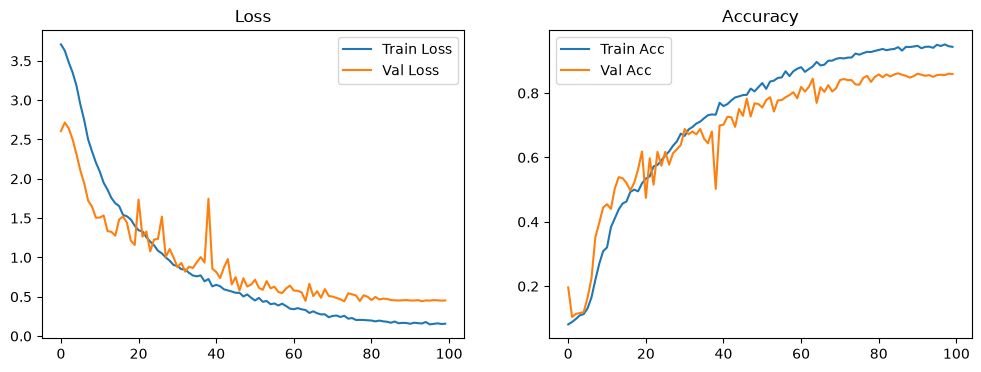

In [29]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

print(f"Acurácia Final no Test Set: {test_correct / test_total:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend()
plt.title("Loss")

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend()
plt.title("Accuracy")
plt.show()

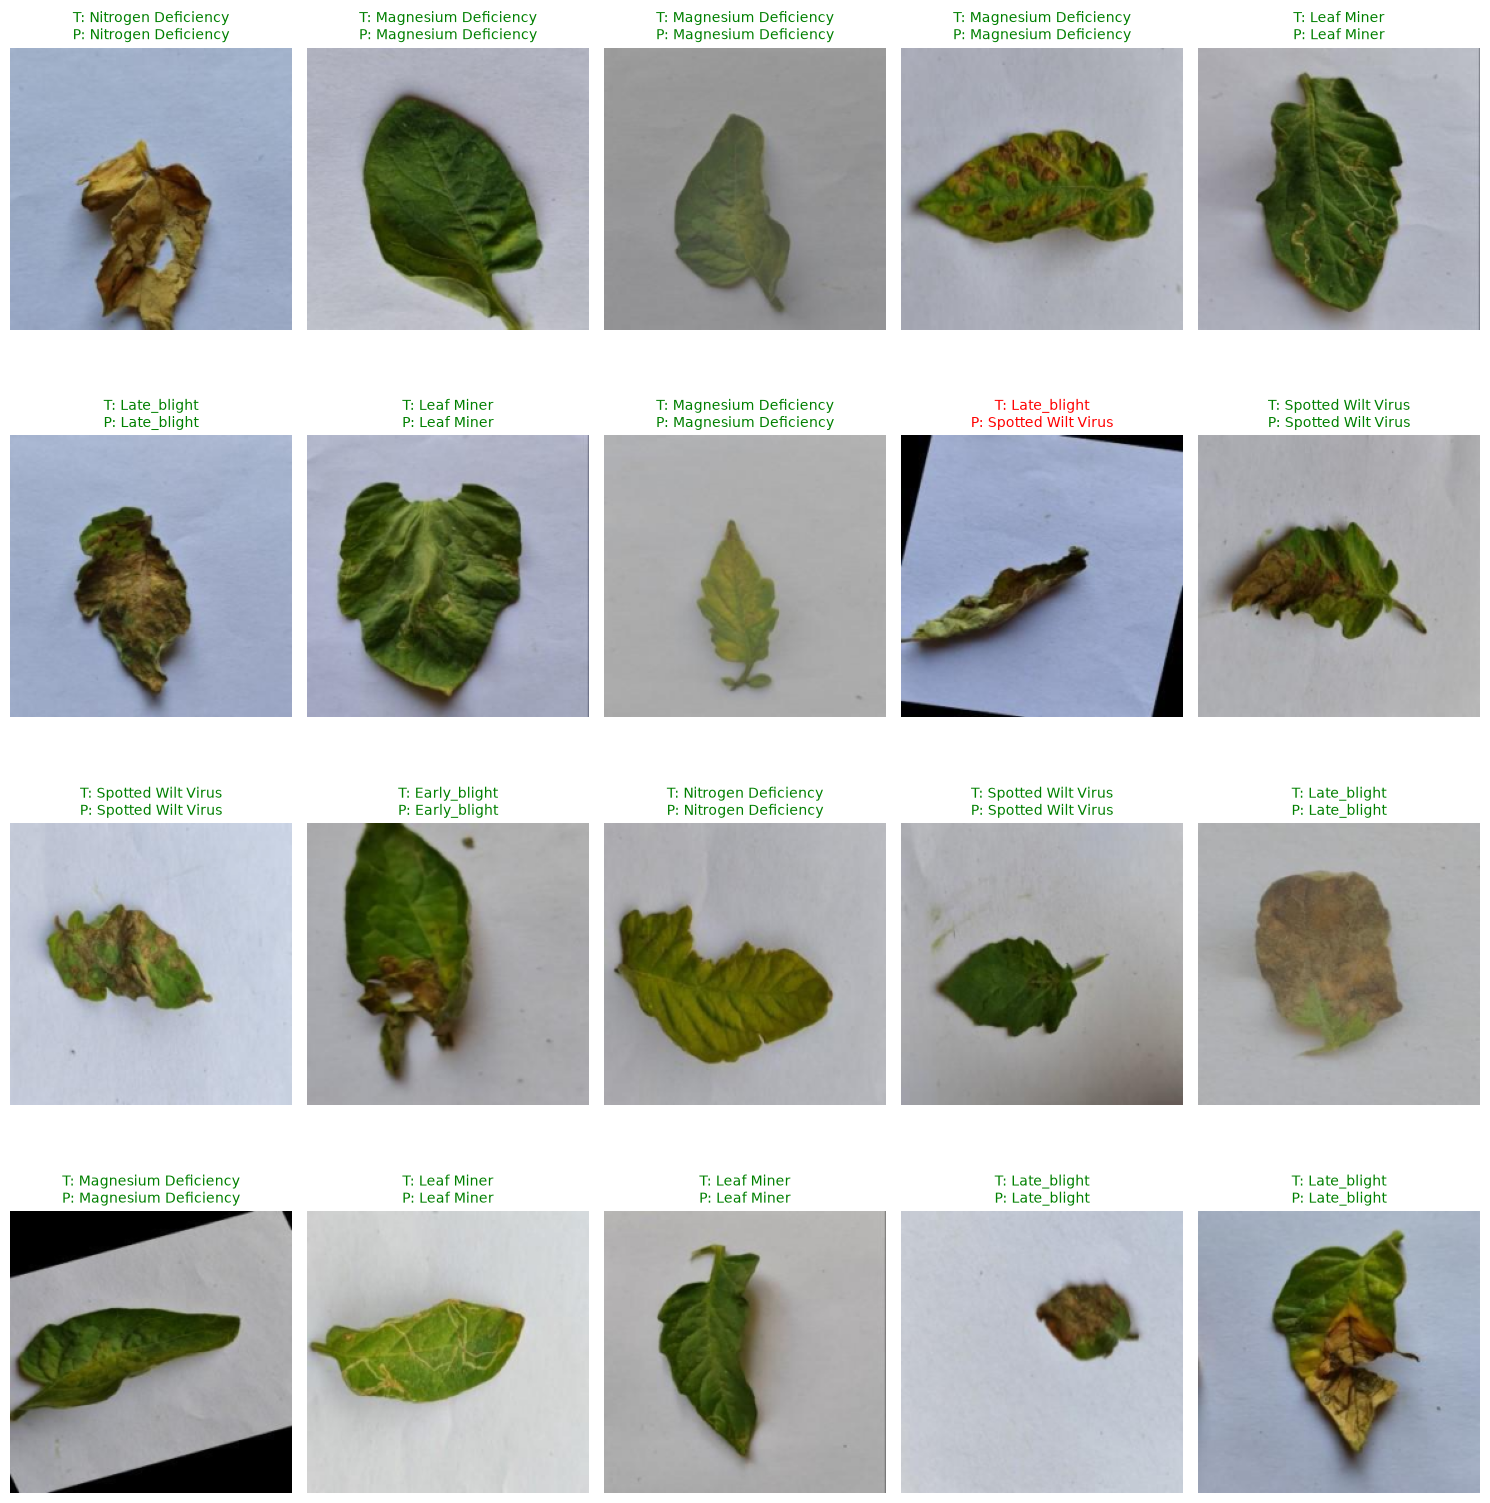

In [14]:
def predict_and_plot(model, dataset, classes, num_samples=10):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    model.eval()
    indices = random.sample(range(len(dataset)), num_samples)

    cols = 5
    rows = math.ceil(num_samples / cols)

    plt.figure(figsize=(15, 4 * rows))
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_input = img_tensor.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            output = model(img_input)
            pred = output.argmax(dim=1).item()

        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)

        color = 'green' if pred == label else 'red'
        plt.title(f"T: {classes[label]}\nP: {classes[pred]}", color=color, fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

predict_and_plot(model, test_dataset, class_names, num_samples=20)

                       precision    recall  f1-score   support

         Early_blight       0.85      0.82      0.84        50
              Healthy       0.76      0.73      0.74        22
          Late_blight       0.92      0.79      0.85        92
           Leaf Miner       0.89      0.89      0.89       104
 Magnesium Deficiency       0.98      0.95      0.96        95
  Nitrogen Deficiency       0.80      0.95      0.86        37
Pottassium Deficiency       1.00      0.88      0.93         8
   Spotted Wilt Virus       0.71      0.89      0.79        53

             accuracy                           0.87       461
            macro avg       0.87      0.86      0.86       461
         weighted avg       0.88      0.87      0.87       461



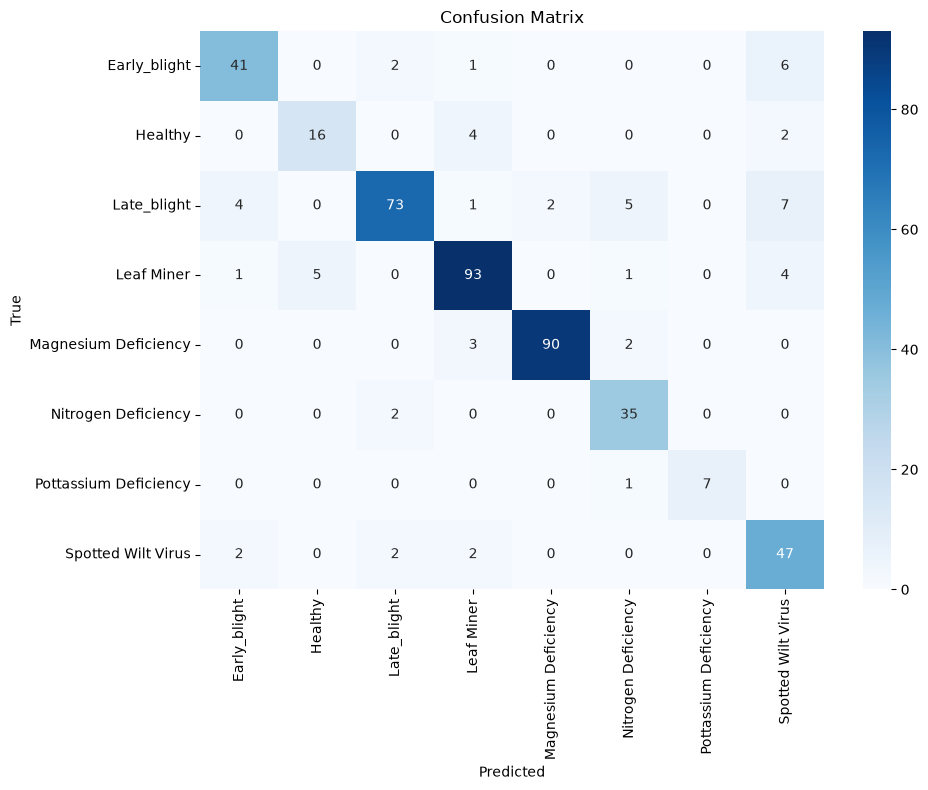

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Export Edge AI

In [16]:
import copy
from pathlib import Path

import numpy as np
import torch
import litert_torch

from ai_edge_litert.interpreter import Interpreter
from ai_edge_quantizer import quantizer, recipe


EXPORT_DIR = Path("tflite_models")
EXPORT_DIR.mkdir(exist_ok=True)

NUM_CALIB_SAMPLES = 100

FP32_PATH = EXPORT_DIR / "model_fp32.tflite"
INT8A16_PATH = EXPORT_DIR / "model_int8a16.tflite"
INT8_PATH = EXPORT_DIR / "model_int8.tflite"

calibration_dataset = datasets.ImageFolder(train_dir, transform=val_test_transforms)

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


In [17]:
export_model = copy.deepcopy(model).cpu().eval()

sample_image = test_dataset[0][0]
sample_inputs = (sample_image.unsqueeze(0).cpu(),)

print(sample_inputs[0].shape)

torch.Size([1, 3, 224, 224])


In [18]:
edge_model = litert_torch.convert(export_model, sample_inputs)
edge_model.export(str(FP32_PATH))

print(f"FP32: {FP32_PATH.stat().st_size / 1024 / 1024:.2f} MB")

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/opt/conda/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


(00:01) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:00)

(00:01) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:01)

... (19 outputs left out)

(00:00) [START] Write Model to tflite_models/model_fp32.tflite

I0000 00:00:1788520799.296579    9575 flatbuffer_export.cc:4342] Estimated count of arithmetic ops: 123.700 M  ops, equivalently 61.850 M  MACs


(00:00) [ DONE] Write Model to tflite_models/model_fp32.tflite (+00:00)

FP32: 0.25 MB


In [19]:
def create_calibration_data(model_path, dataset, num_samples=200, seed=42):
    interpreter = Interpreter(model_path=str(model_path))
    signatures = interpreter.get_signature_list()

    if len(signatures) != 1:
        raise ValueError(f"Esperada uma signature, encontradas: {list(signatures)}")

    signature_name, signature = next(iter(signatures.items()))
    input_names = signature["inputs"]

    if len(input_names) != 1:
        raise ValueError(f"Esperada uma entrada, encontradas: {input_names}")

    input_name = input_names[0]

    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=generator)[:min(num_samples, len(dataset))].tolist()

    samples = []

    for index in indices:
        image = dataset[index][0]
        samples.append({input_name: image.unsqueeze(0).cpu().numpy().astype(np.float32)})

    return {signature_name: samples}



def quantize_static(fp32_path, output_path, calibration_data, quantization_recipe):
    qt = quantizer.Quantizer(str(fp32_path))
    qt.load_quantization_recipe(quantization_recipe())
    calibration_result = qt.calibrate(calibration_data)
    result = qt.quantize(calibration_result)
    result.export_model(str(output_path), overwrite=True)

    print(f"{output_path.name}: {output_path.stat().st_size / 1024 / 1024:.2f} MB")

    
def inspect_tflite(model_path):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]

    print(model_path.name)
    print(f"Input:  {input_info['shape']} {input_info['dtype']}")
    print(f"Output: {output_info['shape']} {output_info['dtype']}")
    print(f"Size:   {model_path.stat().st_size / 1024 / 1024:.2f} MB")


from sklearn.metrics import accuracy_score, classification_report

def evaluate_tflite(model_path, data_loader, class_names):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_index = input_details["index"]
    output_index = output_details["index"]
    input_dtype = input_details["dtype"]
    output_dtype = output_details["dtype"]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    all_labels = []
    all_predictions = []

    for images, labels in data_loader:
        images = images.cpu().numpy()

        for image, label in zip(images, labels.numpy()):
            x = np.expand_dims(image, axis=0)

            if np.issubdtype(input_dtype, np.integer):
                if input_scale == 0:
                    raise ValueError(f"Escala de quantização inválida em {model_path}")
                x = np.round(x / input_scale + input_zero_point)
                x = np.clip(x, np.iinfo(input_dtype).min, np.iinfo(input_dtype).max).astype(input_dtype)
            else:
                x = x.astype(input_dtype)

            interpreter.set_tensor(input_index, x)
            interpreter.invoke()

            output = interpreter.get_tensor(output_index)

            if np.issubdtype(output_dtype, np.integer) and output_scale > 0:
                output = (output.astype(np.float32) - output_zero_point) * output_scale

            prediction = int(np.argmax(output, axis=1)[0])

            all_labels.append(int(label))
            all_predictions.append(prediction)

    accuracy = accuracy_score(all_labels, all_predictions)

    print(f"\n{model_path.name}")
    print(f"Accuracy: {accuracy:.4f}\n")
    print(classification_report(all_labels, all_predictions, target_names=class_names, digits=4, zero_division=0))

    return accuracy, all_labels, all_predictions
    


In [20]:
calibration_data = create_calibration_data(FP32_PATH, calibration_dataset, NUM_CALIB_SAMPLES)

In [21]:
quantize_static(FP32_PATH, INT8A16_PATH, calibration_data, recipe.static_wi8_ai16)

/opt/conda/lib/python3.11/site-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
Applying Transformations to tensors:: 100%|██████████| 116/116 [00:00<00:00, 98709.53it/s]

Model name: tflite_models/model_fp32.tflite
Original model size: 259.29 KiB
Quantized model size: 143.11 KiB
Quantization Ratio: 0.55 (1.8x smaller)
Total time: 20.97 ms
model_int8a16.tflite: 0.14 MB


In [22]:
quantize_static(FP32_PATH, INT8_PATH, calibration_data, recipe.static_wi8_ai8)

Applying Transformations to tensors:: 100%|██████████| 116/116 [00:00<00:00, 101531.57it/s]

Model name: tflite_models/model_fp32.tflite
Original model size: 259.29 KiB
Quantized model size: 136.77 KiB
Quantization Ratio: 0.53 (1.9x smaller)
Total time: 19.86 ms
model_int8.tflite: 0.13 MB


In [23]:
inspect_tflite(FP32_PATH)
inspect_tflite(INT8A16_PATH)
inspect_tflite(INT8_PATH)

model_fp32.tflite
Input:  [  1   3 224 224] <class 'numpy.float32'>
Output: [1 8] <class 'numpy.float32'>
Size:   0.25 MB
model_int8a16.tflite
Input:  [  1   3 224 224] <class 'numpy.int16'>
Output: [1 8] <class 'numpy.int16'>
Size:   0.14 MB
model_int8.tflite
Input:  [  1   3 224 224] <class 'numpy.int8'>
Output: [1 8] <class 'numpy.int8'>
Size:   0.13 MB


In [24]:
fp32_results = evaluate_tflite(FP32_PATH, test_loader, class_names)


model_fp32.tflite
Accuracy: 0.8720

                       precision    recall  f1-score   support

         Early_blight     0.8542    0.8200    0.8367        50
              Healthy     0.7619    0.7273    0.7442        22
          Late_blight     0.9241    0.7935    0.8538        92
           Leaf Miner     0.8942    0.8942    0.8942       104
 Magnesium Deficiency     0.9783    0.9474    0.9626        95
  Nitrogen Deficiency     0.7955    0.9459    0.8642        37
Pottassium Deficiency     1.0000    0.8750    0.9333         8
   Spotted Wilt Virus     0.7121    0.8868    0.7899        53

             accuracy                         0.8720       461
            macro avg     0.8650    0.8613    0.8599       461
         weighted avg     0.8798    0.8720    0.8731       461



In [25]:
int8_results = evaluate_tflite(INT8_PATH, test_loader, class_names)


model_int8.tflite
Accuracy: 0.8655

                       precision    recall  f1-score   support

         Early_blight     0.7959    0.7800    0.7879        50
              Healthy     0.7727    0.7727    0.7727        22
          Late_blight     0.9481    0.7935    0.8639        92
           Leaf Miner     0.8796    0.9135    0.8962       104
 Magnesium Deficiency     0.9780    0.9368    0.9570        95
  Nitrogen Deficiency     0.8500    0.9189    0.8831        37
Pottassium Deficiency     1.0000    0.8750    0.9333         8
   Spotted Wilt Virus     0.6716    0.8491    0.7500        53

             accuracy                         0.8655       461
            macro avg     0.8620    0.8549    0.8555       461
         weighted avg     0.8752    0.8655    0.8674       461



In [26]:
int8a16_results = evaluate_tflite(INT8A16_PATH, test_loader, class_names)


model_int8a16.tflite
Accuracy: 0.8698

                       precision    recall  f1-score   support

         Early_blight     0.8200    0.8200    0.8200        50
              Healthy     0.8095    0.7727    0.7907        22
          Late_blight     0.9359    0.7935    0.8588        92
           Leaf Miner     0.8796    0.9135    0.8962       104
 Magnesium Deficiency     0.9780    0.9368    0.9570        95
  Nitrogen Deficiency     0.8293    0.9189    0.8718        37
Pottassium Deficiency     1.0000    0.8750    0.9333         8
   Spotted Wilt Virus     0.6923    0.8491    0.7627        53

             accuracy                         0.8698       461
            macro avg     0.8681    0.8599    0.8613       461
         weighted avg     0.8778    0.8698    0.8713       461



In [27]:
def print_tflite_io_types(model_path):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    print(f"\n{model_path.name}")
    print(f"inference_input_type:  {input_details['dtype']}")
    print(f"inference_output_type: {output_details['dtype']}")
    print(f"input quantization:     {input_details['quantization']}")
    print(f"output quantization:    {output_details['quantization']}")

print_tflite_io_types(FP32_PATH)
print_tflite_io_types(INT8A16_PATH)
print_tflite_io_types(INT8_PATH)


model_fp32.tflite
inference_input_type:  <class 'numpy.float32'>
inference_output_type: <class 'numpy.float32'>
input quantization:     (0.0, 0)
output quantization:    (0.0, 0)

model_int8a16.tflite
inference_input_type:  <class 'numpy.int16'>
inference_output_type: <class 'numpy.int16'>
input quantization:     (5.8397599786985666e-05, 0)
output quantization:    (0.00037681800313293934, 0)

model_int8.tflite
inference_input_type:  <class 'numpy.int8'>
inference_output_type: <class 'numpy.int8'>
input quantization:     (0.01454248744994402, -5)
output quantization:    (0.07415502518415451, -40)
